# Baseline: Starting Grid Position

The simplest possible predictor: **a driver finishes where they start.**

- Predicted finishing position = starting grid position (ranked within each race)
- No training, no features, no randomness
- Every other method (Random Forest, XGBoost) has to beat this

Evaluation follows the project plan: chronological splits (train 2014-2023, validation 2024, test 2025) and four metrics (accuracy, MAE, podium recall, Spearman's rho).

## 1. Setup

### 1.1 Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import f1_utils as f1

### 1.2 Plot theme

Light background with Formula 1 reds. The same theme is used in every notebook (see `f1_utils.set_f1_theme`).

In [2]:
f1.set_f1_theme()
NOTEBOOK = "baseline"  # figures are saved to figures/baseline/

### 1.3 Seeds

The baseline has no randomness, but we still loop over the same five seeds as the models so the results tables have the same format.

In [3]:
SEEDS = f1.SEEDS
SEEDS

[1, 7, 42, 99, 2026]

## 2. Data

### 2.1 Load CSV

In [4]:
df_all = f1.load_data()
print(df_all.shape)
df_all.head()

(5105, 53)


,row_id,raceId,year,round,date,race_name,driverId,driver_ref,constructorId,constructor_ref,...,circuit_safety_car_rate,circuit_safety_car_avg,circuit_red_flag_rate,race_time_of_day,air_temp,wind_speed,humidity,rain,finish_position,dnf
0,900_1,900,2014,1,2014-03-16,Australian Grand Prix,1,hamilton,131,mercedes,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,19,1
1,900_817,900,2014,1,2014-03-16,Australian Grand Prix,817,ricciardo,9,red_bull,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,22,1
2,900_3,900,2014,1,2014-03-16,Australian Grand Prix,3,rosberg,131,mercedes,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,1,0
3,900_825,900,2014,1,2014-03-16,Australian Grand Prix,825,kevin_magnussen,1,mclaren,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,2,0
4,900_4,900,2014,1,2014-03-16,Australian Grand Prix,4,alonso,6,ferrari,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,4,0


### 2.2 Keep only the needed columns

The baseline only needs driver info, the starting grid position, and the actual finishing position. `quali_position` is kept only to break ties between pit-lane starters, and `dnf` is kept for error analysis.

In [5]:
COLS = [
    "raceId", "year", "round", "race_name",            # race info
    "driverId", "driver_ref", "constructor_ref",       # driver info
    "grid", "quali_position",                          # starting position
    "finish_position", "dnf",                          # labels
]
df = df_all[COLS].copy()
df.head()

,raceId,year,round,race_name,driverId,driver_ref,constructor_ref,grid,quali_position,finish_position,dnf
0,900,2014,1,Australian Grand Prix,1,hamilton,mercedes,1.0,1.0,19,1
1,900,2014,1,Australian Grand Prix,817,ricciardo,red_bull,2.0,2.0,22,1
2,900,2014,1,Australian Grand Prix,3,rosberg,mercedes,3.0,3.0,1,0
3,900,2014,1,Australian Grand Prix,825,kevin_magnussen,mclaren,4.0,4.0,2,0
4,900,2014,1,Australian Grand Prix,4,alonso,ferrari,5.0,5.0,4,0


### 2.3 Handle pit-lane starts

`grid == 0` means the driver started from the pit lane, i.e. **behind** everyone on the grid. We give them a large start value so they are ranked last (ties broken by qualifying position).

In [6]:
PIT_LANE = 99

pit_lane = df["grid"] == 0
df["start_pos"] = df["grid"].where(~pit_lane, PIT_LANE)
print(f"Pit-lane starts: {pit_lane.sum()} of {len(df)} rows")

Pit-lane starts: 79 of 5105 rows


## 3. Chronological splits

### 3.1 Train / validation / test

| Split | Years | Purpose |
|---|---|---|
| Train | 2014-2023 | Model fitting |
| Validation | 2024 | Hyperparameter tuning |
| Test | 2025 | Final evaluation only |

In [7]:
train, val, test = f1.split_by_year(df)
splits = {"train": train, "val": val, "test": test}

pd.DataFrame({
    name: {"years": f"{d.year.min()}-{d.year.max()}", "races": d.raceId.nunique(), "rows": len(d)}
    for name, d in splits.items()
}).T

,years,races,rows
train,2014-2023,204,4147
val,2024-2024,24,479
test,2025-2025,24,479


### 3.2 Races per year

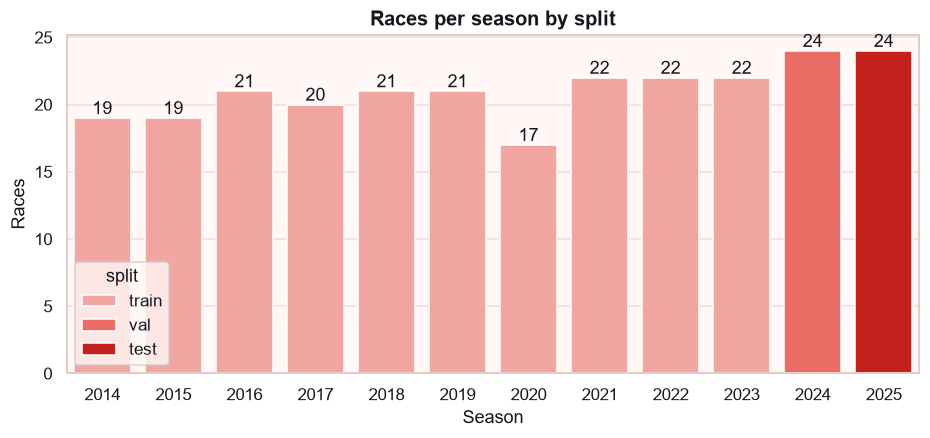

In [8]:
per_year = df.groupby("year").agg(races=("raceId", "nunique"), rows=("raceId", "size")).reset_index()
per_year["split"] = np.select(
    [per_year["year"] == f1.VAL_YEAR, per_year["year"] == f1.TEST_YEAR], ["val", "test"], "train"
)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=per_year, x="year", y="races", hue="split", palette=f1.SPLIT_COLORS, dodge=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container)
ax.set(title="Races per season by split", xlabel="Season", ylabel="Races")
f1.save_fig(fig, NOTEBOOK, "races_per_year")
plt.show()

## 4. Baseline model

### 4.1 Predict finish = starting position

`f1.to_race_ranks` turns the start position into a valid finishing order 1..N within each race. The model notebooks use the same function on their predictions, so the comparison is fair.

In [9]:
def predict_baseline(data):
    out = data.copy()
    out["pred_position"] = f1.to_race_ranks(out, "start_pos")
    return out


train, val, test = (predict_baseline(d) for d in (train, val, test))
splits = {"train": train, "val": val, "test": test}

### 4.2 Sanity check: one race

In [10]:
example_race = test["raceId"].iloc[0]
(test[test["raceId"] == example_race]
     .sort_values("pred_position")
     [["race_name", "driver_ref", "constructor_ref", "grid", "pred_position", "finish_position", "dnf"]])

,race_name,driver_ref,constructor_ref,grid,pred_position,finish_position,dnf
0,Australian Grand Prix,norris,mclaren,1.0,1,1,0
1,Australian Grand Prix,piastri,mclaren,2.0,2,9,0
2,Australian Grand Prix,max_verstappen,red_bull,3.0,3,2,0
3,Australian Grand Prix,russell,mercedes,4.0,4,3,0
4,Australian Grand Prix,tsunoda,rb,5.0,5,12,0
5,Australian Grand Prix,albon,williams,6.0,6,5,0
6,Australian Grand Prix,leclerc,ferrari,7.0,7,8,0
7,Australian Grand Prix,hamilton,ferrari,8.0,8,10,0
8,Australian Grand Prix,gasly,alpine,9.0,9,11,0
9,Australian Grand Prix,sainz,williams,10.0,10,18,1


## 5. Evaluation

All metrics are computed **per race** and then averaged over races:

- **Accuracy**: share of drivers whose predicted position exactly matches the actual position
- **MAE**: mean absolute difference between predicted and actual position (lower is better)
- **Podium recall**: how many of the actual top 3 were in the predicted top 3 (out of 3)
- **Spearman's rho**: rank correlation between predicted and actual finishing order (1 = perfect)

### 5.1 Metrics by split

In [11]:
metrics_by_split = pd.DataFrame({name: f1.evaluate(d, "pred_position") for name, d in splits.items()}).T
metrics_by_split.round(3)

,accuracy,mae,podium_recall,spearman
train,0.152,3.678,0.693,0.604
val,0.154,2.900,0.667,0.729
test,0.184,3.344,0.750,0.651


### 5.2 Seed runs (mean and std)

Same format as the model notebooks. The std is 0 because the baseline is deterministic.

In [12]:
seed_results = {"val": [], "test": []}
for seed in SEEDS:
    np.random.seed(seed)
    for name in seed_results:
        preds = predict_baseline(splits[name])
        seed_results[name].append(f1.evaluate(preds, "pred_position"))

summary = pd.concat({name: f1.summarize_seeds(r) for name, r in seed_results.items()}, axis=1)
summary.round(3)

val        test     
                mean  std   mean  std
accuracy       0.154  0.0  0.184  0.0
mae            2.900  0.0  3.344  0.0
podium_recall  0.667  0.0  0.750  0.0
spearman       0.729  0.0  0.651  0.0

### 5.3 Save baseline metrics

Saved to `results/baseline_metrics.csv` so the model notebooks can compare against it.

In [13]:
results_dir = f1.PROJECT_ROOT / "results"
results_dir.mkdir(exist_ok=True)
metrics_by_split.to_csv(results_dir / "baseline_metrics.csv")

## 6. Plots

### 6.1 Predicted vs actual position (test, 2025)

Each cell counts drivers. A perfect predictor would put everything on the diagonal.

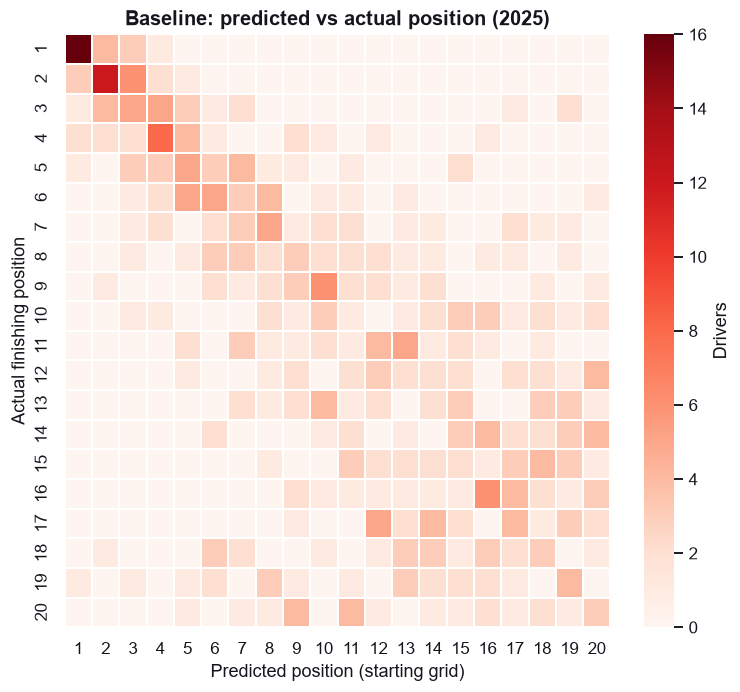

In [14]:
max_pos = int(test[["pred_position", "finish_position"]].max().max())
positions = range(1, max_pos + 1)
cm = (pd.crosstab(test["finish_position"], test["pred_position"])
        .reindex(index=positions, columns=positions, fill_value=0))

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(cm, cmap=f1.F1_CMAP, linewidths=0.3, linecolor="white", cbar_kws={"label": "Drivers"}, ax=ax)
ax.set(title="Baseline: predicted vs actual position (2025)",
       xlabel="Predicted position (starting grid)", ylabel="Actual finishing position")
f1.save_fig(fig, NOTEBOOK, "pred_vs_actual_heatmap")
plt.show()

### 6.2 Error distribution

Error = actual - predicted. Positive means the driver finished **behind** their start position (lost places).

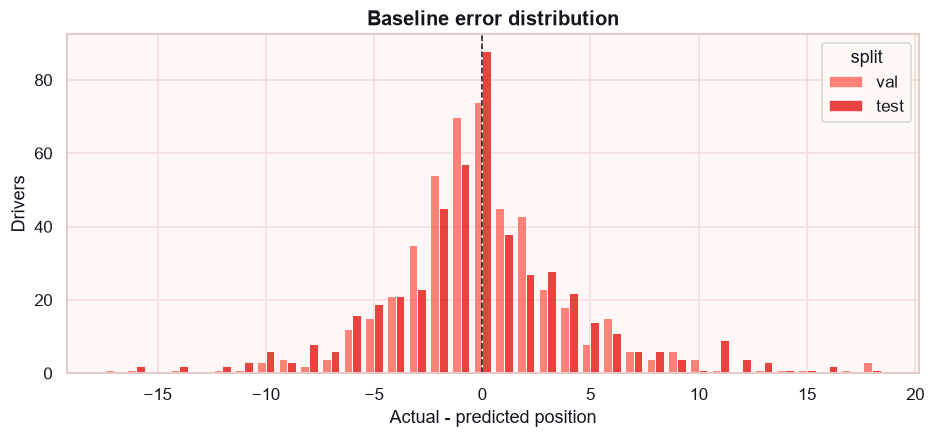

In [15]:
eval_df = pd.concat([val.assign(split="val"), test.assign(split="test")], ignore_index=True)
eval_df["error"] = eval_df["finish_position"] - eval_df["pred_position"]
eval_df["abs_error"] = eval_df["error"].abs()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=eval_df, x="error", hue="split", palette=f1.SPLIT_COLORS,
             discrete=True, multiple="dodge", shrink=0.8, ax=ax)
ax.axvline(0, color=f1.F1_CARBON, ls="--", lw=1)
ax.set(title="Baseline error distribution", xlabel="Actual - predicted position", ylabel="Drivers")
f1.save_fig(fig, NOTEBOOK, "error_distribution")
plt.show()

### 6.3 MAE by starting position

Front-runners tend to stay at the front; the midfield and back of the grid are much harder to predict.

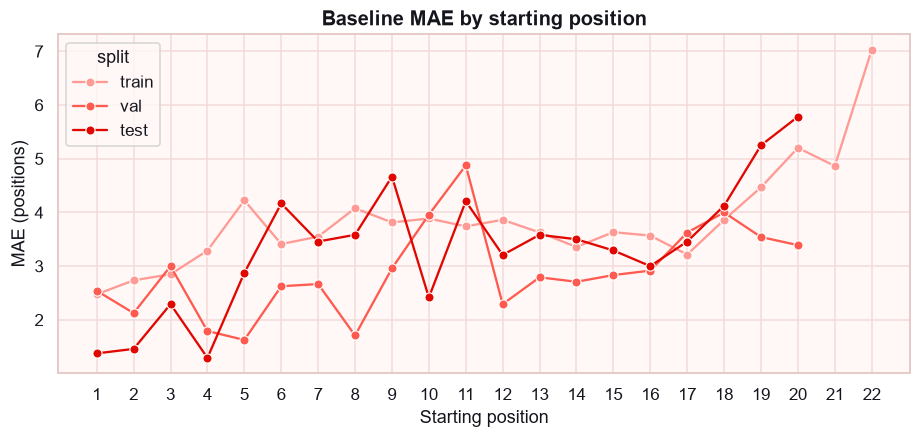

In [16]:
all_df = pd.concat([d.assign(split=name) for name, d in splits.items()], ignore_index=True)
all_df["abs_error"] = (all_df["finish_position"] - all_df["pred_position"]).abs()
mae_by_pos = all_df.groupby(["split", "pred_position"])["abs_error"].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=mae_by_pos, x="pred_position", y="abs_error", hue="split",
             hue_order=["train", "val", "test"], palette=f1.SPLIT_COLORS, marker="o", ax=ax)
ax.set(title="Baseline MAE by starting position", xlabel="Starting position", ylabel="MAE (positions)")
ax.set_xticks(range(1, int(mae_by_pos["pred_position"].max()) + 1))
f1.save_fig(fig, NOTEBOOK, "mae_by_start_position")
plt.show()

### 6.4 Per-race metrics across the 2025 season

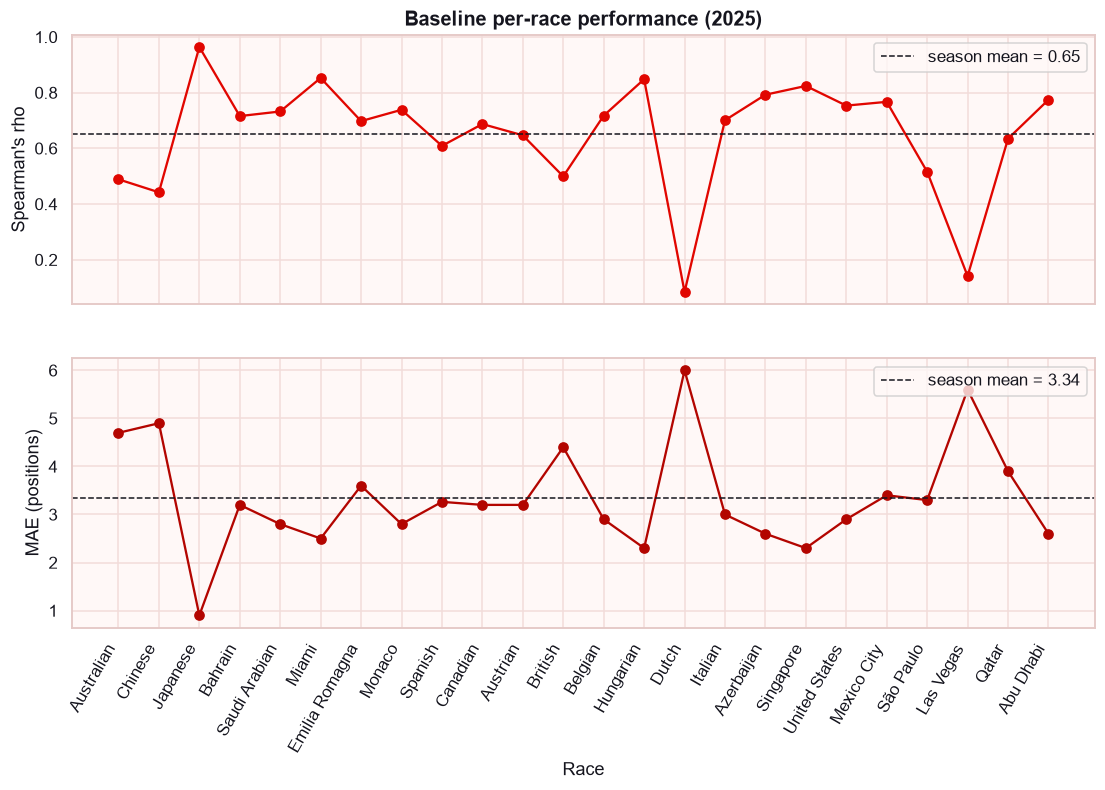

In [17]:
test_races = f1.per_race_metrics(test, "pred_position")
labels = test_races["race_name"].str.replace(" Grand Prix", "", regex=False)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, metric, color, title in [
    (axes[0], "spearman", f1.F1_RED, "Spearman's rho"),
    (axes[1], "mae", "#B30500", "MAE (positions)"),
]:
    ax.plot(test_races["round"], test_races[metric], marker="o", color=color)
    ax.axhline(test_races[metric].mean(), color=f1.F1_CARBON, ls="--", lw=1,
               label=f"season mean = {test_races[metric].mean():.2f}")
    ax.set_ylabel(title)
    ax.legend(loc="upper right")
axes[0].set_title("Baseline per-race performance (2025)")
axes[1].set_xticks(test_races["round"], labels, rotation=60, ha="right")
axes[1].set_xlabel("Race")
f1.save_fig(fig, NOTEBOOK, "per_race_2025")
plt.show()

### 6.5 Metrics per season (2014-2025)

Shows how stable the baseline is across seasons and whether 2024/2025 are unusual.

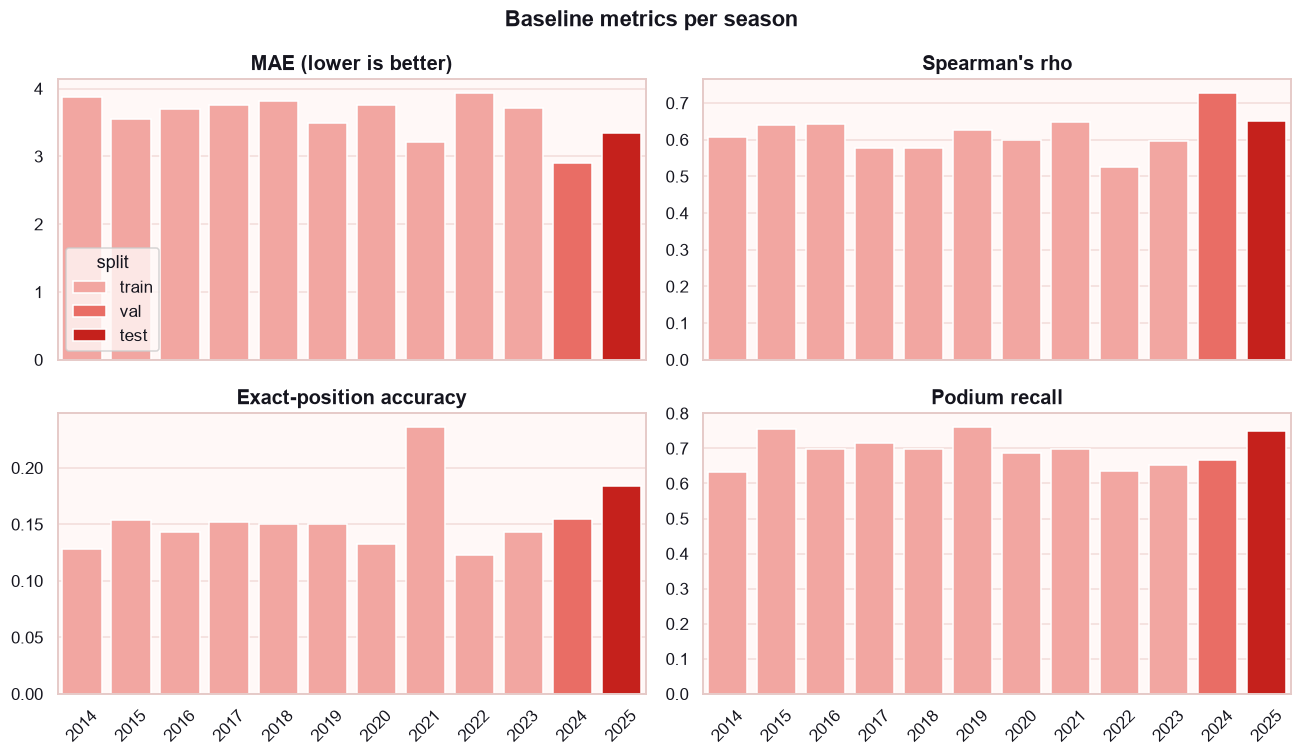

In [18]:
all_races = f1.per_race_metrics(all_df, "pred_position")
yearly = all_races.groupby("year")[["accuracy", "mae", "podium_recall", "spearman"]].mean().reset_index()
yearly = yearly.merge(per_year[["year", "split"]], on="year")

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (metric, title) in zip(axes.flat, [
    ("mae", "MAE (lower is better)"), ("spearman", "Spearman's rho"),
    ("accuracy", "Exact-position accuracy"), ("podium_recall", "Podium recall"),
]):
    sns.barplot(data=yearly, x="year", y=metric, hue="split", palette=f1.SPLIT_COLORS,
                dodge=False, legend=(metric == "mae"), ax=ax)
    ax.set(title=title, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=45)
sns.move_legend(axes[0, 0], "lower left", frameon=True)
fig.suptitle("Baseline metrics per season", fontweight="bold")
fig.tight_layout()
f1.save_fig(fig, NOTEBOOK, "metrics_per_season")
plt.show()

### 6.6 Finishers vs DNFs

A driver who retires (DNF) is classified at the back, so the grid baseline is badly wrong for them. This error is hard for any pre-race model to avoid.

split
test    0.115
val     0.100
Name: DNF share, dtype: float64


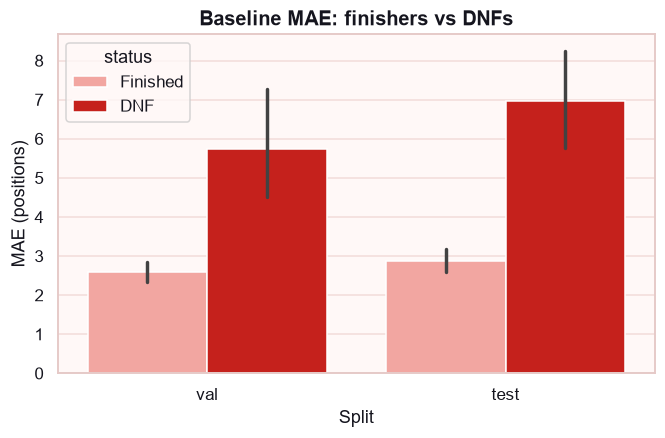

In [19]:
eval_df["status"] = eval_df["dnf"].map({0: "Finished", 1: "DNF"})
print(eval_df.groupby("split")["dnf"].mean().rename("DNF share").round(3))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=eval_df, x="split", y="abs_error", hue="status",
            palette={"Finished": "#FF9A94", "DNF": f1.F1_RED}, errorbar=("ci", 95), ax=ax)
ax.set(title="Baseline MAE: finishers vs DNFs", xlabel="Split", ylabel="MAE (positions)")
f1.save_fig(fig, NOTEBOOK, "mae_finishers_vs_dnf")
plt.show()

## 7. Summary

In [20]:
summary.xs("mean", axis=1, level=1).T.round(3)

,accuracy,mae,podium_recall,spearman
val,0.154,2.900,0.667,0.729
test,0.184,3.344,0.750,0.651


**Numbers to beat (2025 test set):**

| Metric | Validation (2024) | Test (2025) |
|---|---|---|
| Accuracy | 0.154 | 0.184 |
| MAE | 2.896 | 3.344 |
| Podium recall | 0.667 | 0.750 |
| Spearman's rho | 0.730 | 0.651 |

Takeaways:

- Starting position is already a strong predictor (Spearman around 0.65-0.73), especially at the front of the grid.
- Errors grow toward the back of the grid and are largest for drivers who do not finish (DNF).
- Some races (e.g. 2025 Dutch and Las Vegas GPs) break the grid order almost completely; these are good candidates for error analysis in the model notebooks.